In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame, Series

import pims
import trackpy as tp

video = pims.open ("/home/susanta/Downloads/PICT0097.AVI")

print("Number of frames:", len(video))
print ("Frames shape:", video.frame_shape)
fps = getattr(video, 'frame_rate', 15.0)
print(f"Frame rate    : {fps} fps")

Number of frames: 479
Frames shape: (360, 640, 3)
Frame rate    : 15.0 fps


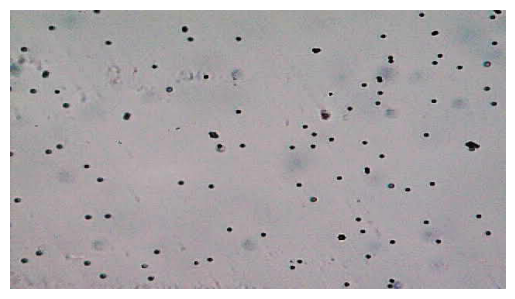

In [47]:
plt.imshow(video[0])
plt.axis('off')
plt.show()

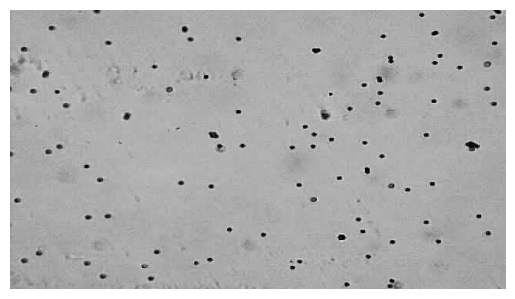

In [48]:
@pims.pipeline
def gray(image):
    if image.ndim == 3:
        return image[:, :, 1]
    return image

frames = gray(video)

plt.imshow(frames[0], cmap='gray')
plt.axis('off')
plt.show()

In [49]:
features = tp.locate(frames[0], diameter=11, minmass=1100, invert=True)
features.head()

,y,x,mass,size,ecc,signal,raw_mass,ep,frame
4,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0
13,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0
34,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0
37,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0
43,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0


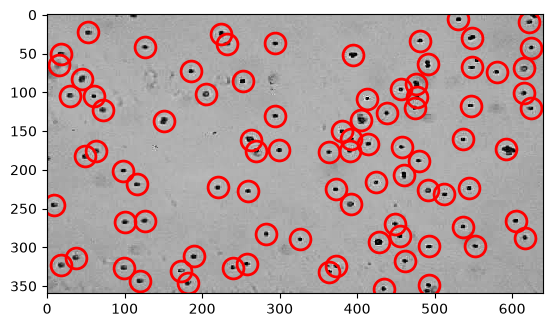

In [50]:
tp.annotate(features, frames[0])
plt.show()

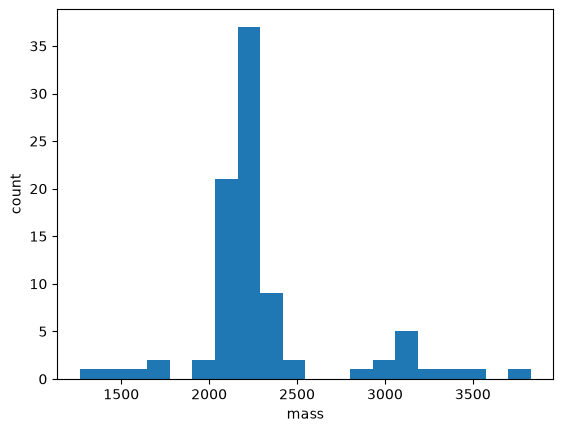

In [51]:
fig, ax = plt.subplots()
ax.hist(features['mass'], bins=20)
ax.set(xlabel='mass', ylabel='count')
plt.show()

In [52]:
features = tp.batch(frames, diameter=11, minmass=1100, invert=True, processes=1)

features.head()

Frame 478: 84 features


,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0
1,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0
2,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0
3,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0
4,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0


## Step 3: Trajectory Linking & Stub Filtering
We link particle coordinates across consecutive frames into trajectories:
- `search_range=5`: Maximum expected displacement (in pixels) between consecutive frames.
- `memory=2`: Allows particles to briefly drop out for up to 2 frames without breaking trajectory continuity.
- `tp.filter_stubs`: Removes short, transient tracks persisting for less than 25 frames.

In [34]:
t = tp.link(features, search_range=5, memory=2)
t.head()

Frame 478: 84 trajectories present.


,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
0,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0,0
1,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0,1
2,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0,2
3,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0,3
4,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0,4


In [35]:
t1 = tp.filter_stubs(t, 25)

# Compare the number of particles before and after filtering
print(f"Number of particles before filtering: {t['particle'].nunique()}")
print(f"Number of particles after filtering: {t1['particle'].nunique()}")

Number of particles before filtering: 2836
Number of particles after filtering: 613


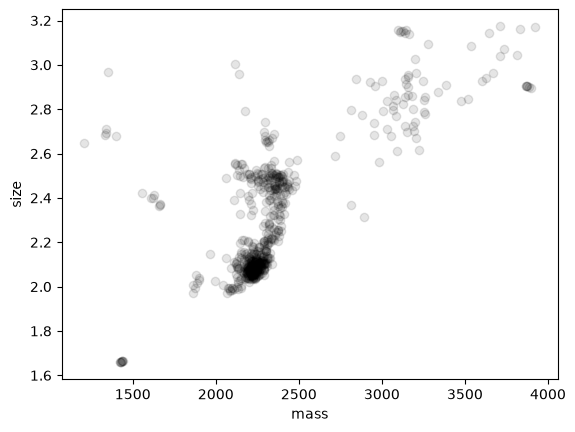

In [36]:
# plt.figure()
tp.mass_size(t1.groupby('particle').mean())
plt.show()

In [38]:
# Filter clean spherical colloidal particles
# t2 = t1[((t1['mass'] > 50) & (t1['size'] < 2.6) 
#          & (t1['ecc'] < 0.3))]


# t2 = t1[((t1['mass'] > 1500) & (t1['size'] < 2.6) 
#          & (t1['ecc'] < 0.3))]
# print(f"Clean, validated trajectories (t2): {t2['particle'].nunique()}")

# # Annotate Frame 0 with clean filtered particles
# # plt.figure()
# tp.annotate(t2[t2['frame'] == 0], frames[0])
# plt.show()

pm = t1.groupby('particle').mean()
keep = []
for pid in pm.index:
    if pm.loc[pid, 'mass'] > 1500 and pm.loc[pid, 'size'] < 2.6 and pm.loc[pid, 'ecc'] < 0.3:
        keep.append(pid)
t2 = t1[t1['particle'].isin(keep)]
print(f"Clean trajectories (t2): {t2['particle'].nunique()}")

Clean trajectories (t2): 511


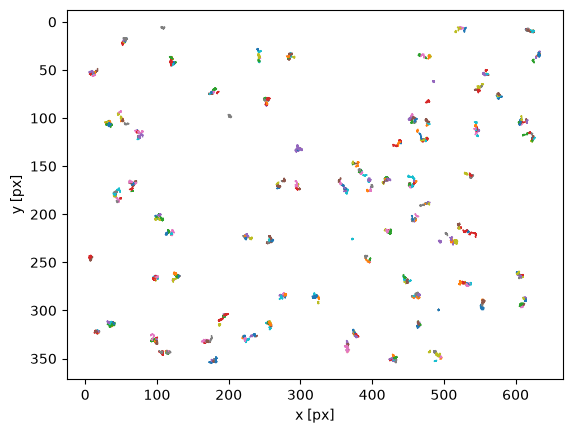

In [39]:
# plt.figure()
tp.plot_traj(t2)
plt.show()

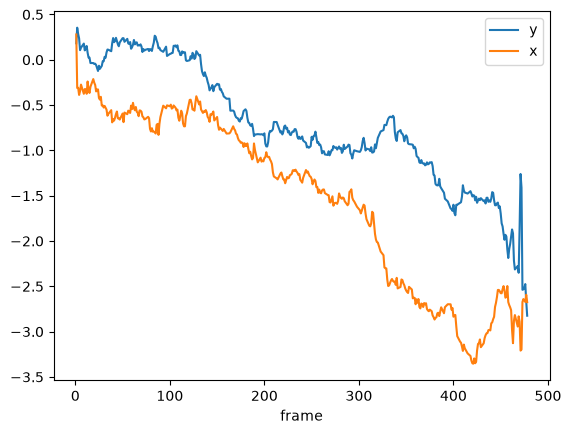

In [40]:
d = tp.compute_drift(t2)
d.plot()
plt.show()

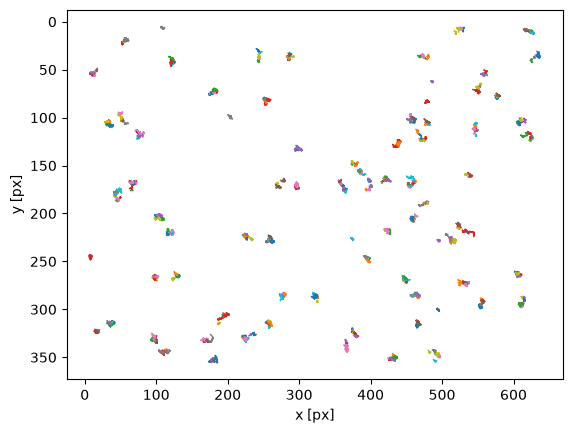

In [41]:
tm = tp.subtract_drift(t2.copy(), d)

ax = tp.plot_traj(tm)
ax.set_title('Drift-subtracted trajectories')
plt.show()

fps = 15.0
Expected particle diameter = 33.3 px
Diameter used in tp.locate = 11 px -> 1.32 µm


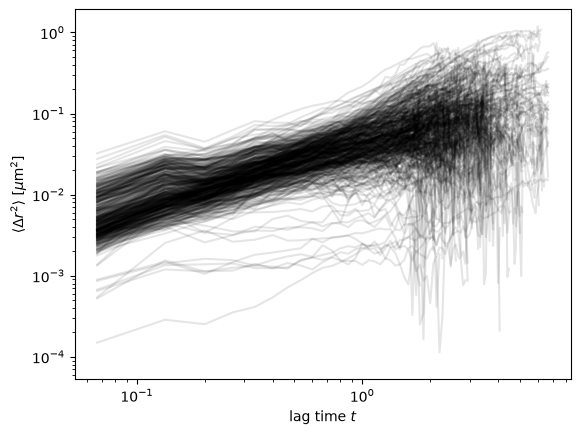

In [42]:
# im = tp.imsd(tm, 100/285., 24)

mpp = 0.12   # µm/pixel -- verify with a calibration slide
r_um = 2.0   # µm -- verify with the manufacturer's value

print(f"fps = {fps}")
print(f"Expected particle diameter = {2*r_um/mpp:.1f} px")
print(f"Diameter used in tp.locate = 11 px -> {11*mpp:.2f} µm")

# fps = 15.0  #frames per second
mpp = 0.12  # Microns per pixel calibration 
unit_label = r'\mu\mathrm{m}' if mpp != 1.0 else r'\mathrm{pixels}'

# Compute Individual Particle MSDs (IMSD)
im = tp.imsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots()
ax.plot(im.index, im, 'k-', alpha=0.1)
ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set_xscale('log')
ax.set_yscale('log')

plt.show()

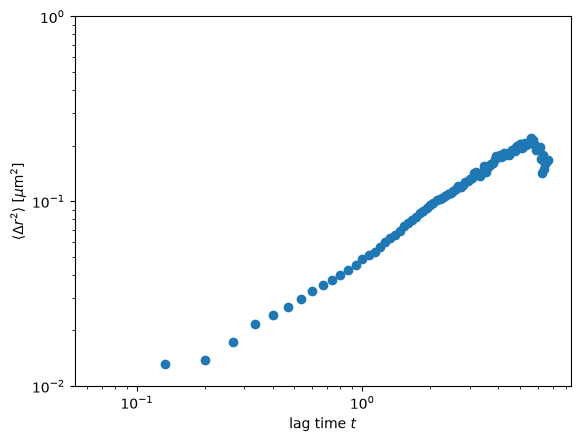

In [43]:
# em = tp.emsd(tm, 100/285., 24)

# Compute Ensemble Mean Squared Displacement (EMSD)
em = tp.emsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots()
ax.plot(em.index, em, 'o')
ax.set_xscale('log')
ax.set_yscale('log')

ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set(ylim=(1e-2, 1));

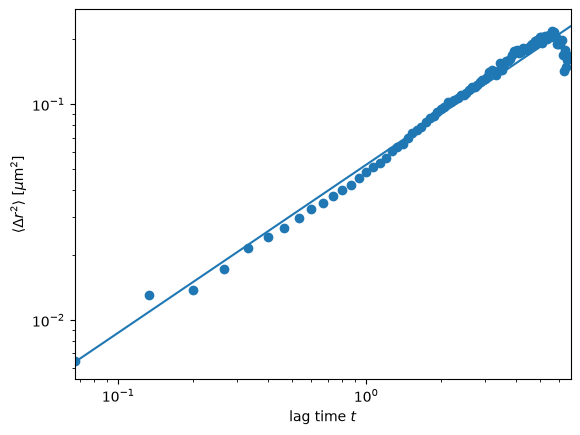

,n,A
msd,0.77856,0.052487


In [44]:
plt.figure()
plt.ylabel(r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]')
plt.xlabel('lag time $t$')
tp.utils.fit_powerlaw(em)



In [45]:
# Physical parameters
T = 298.15
eta = 0.89e-3 
r_um = 2.0 
R = 8.314462618


t_min = 0.2 
t_max = 4.0

time = em.index.values
msd = em.values 


mask = (time >= t_min) & (time <= t_max)

t_fit = time[mask]
msd_fit = msd[mask]


# Linear fit: MSD = 4Dt + intercept


slope, intercept = np.polyfit(t_fit, msd_fit, 1)

# For 2D Brownian motion:
D_um2_s = slope / 4.0


D = D_um2_s * 1e-12



r = r_um * 1e-6              # radius in meters

k_B = (6 * np.pi * eta * r * D) / T


N_A = R / k_B


print(f"Temperature, T       = {T:.2f} K")
print(f"Water viscosity, eta = {eta:.3e} Pa.s")
print(f"Particle radius, r   = {r_um:.2f} µm")
print(f"mpp                  = {mpp:.4f} µm/pixel")

print("----------------------------------------")
print(f"MSD slope            = {slope:.6f} µm²/s")
print(f"Diffusion coefficient D = {D_um2_s:.6f} µm²/s")
print(f"Diffusion coefficient D = {D:.6e} m²/s")

print("----------------------------------------")
print(f"Boltzmann constant k_B = {k_B:.6e} J/K")
print(f"Avogadro number N_A    = {N_A:.6e} mol⁻¹")


Temperature, T       = 298.15 K
Water viscosity, eta = 8.900e-04 Pa.s
Particle radius, r   = 2.00 µm
mpp                  = 0.1200 µm/pixel
----------------------------------------
MSD slope            = 0.041115 µm²/s
Diffusion coefficient D = 0.010279 µm²/s
Diffusion coefficient D = 1.027884e-14 m²/s
----------------------------------------
Boltzmann constant k_B = 1.156725e-24 J/K
Avogadro number N_A    = 7.187931e+24 mol⁻¹


Frame 478: 84 features

Total particle detections: 41227
Particle detections after filtering: 33648

Grid information
----------------------------
Grid cell size: 40 pixels
Number of columns: 16
Number of rows: 9
Total cells per frame: 144

Particle counting completed.
Total cell observations: 68976
Total particles counted: 33648

Experimental results
--------------------------------
Mean particle count (lambda) = 0.48782
Variance of particle count   = 0.52024
--------------------------------

Probability distribution:
 Number of particles  Number of grid cells  Probability
                   0                 43115     0.625072
                   1                 19133     0.277386
                   2                  6118     0.088698
                   3                   181     0.002624
                   4                   419     0.006075
                   6                    10     0.000145


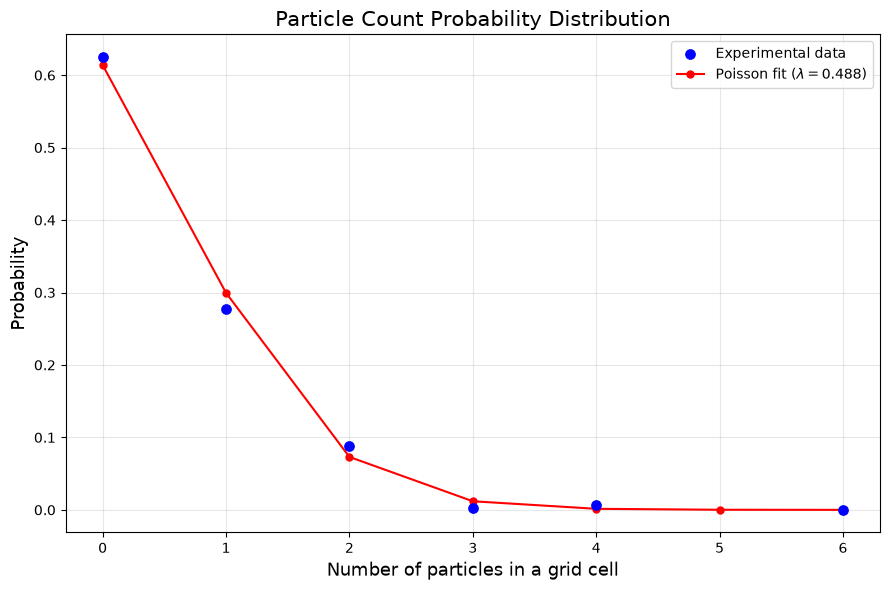

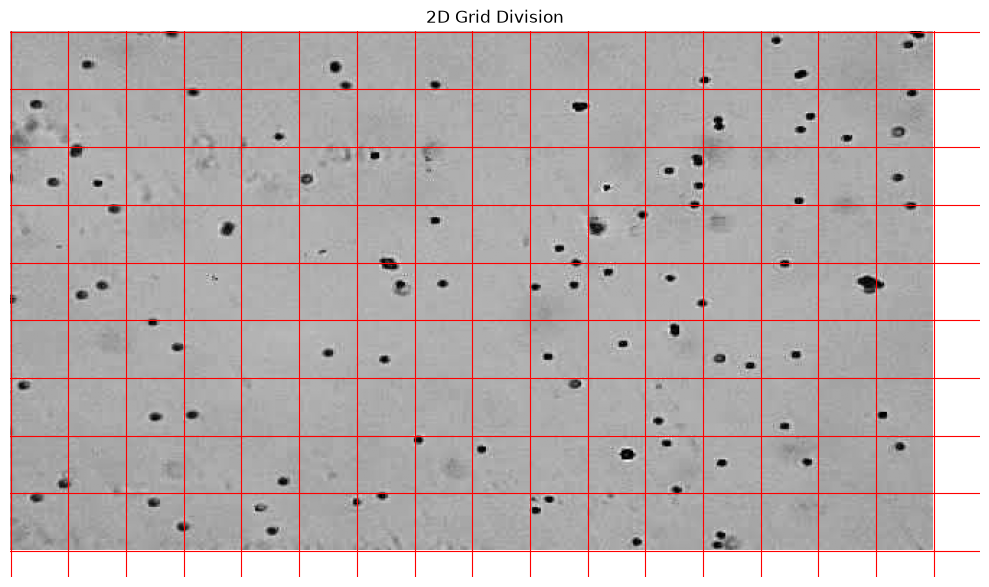


CHI-SQUARE GOODNESS-OF-FIT TEST
--------------------------------
Chi-square statistic = 1873.86608
Degrees of freedom   = 4
p-value              = 0.000000

The Poisson distribution is rejected
at the 5% significance level.

FINAL EXPERIMENTAL SUMMARY
Number of video frames: 479
Grid size: 40 x 40 pixels
Total grid observations: 68976
Total detected particles: 33648
Experimental mean lambda: 0.487822
Experimental variance: 0.520236
Poisson theoretical mean: 0.487822
Poisson theoretical variance: 0.487822


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pims
import trackpy as tp

from scipy.stats import poisson, chi2


# ==========================================================
# 1. LOAD EXPERIMENTAL VIDEO
# ==========================================================

video_path = "/home/susanta/Downloads/PICT0097.AVI"
# video_path = "/home/susanta/Downloads/BM2.AVI"

video = pims.open(video_path)

n_frames = len(video)
height, width = video.frame_shape[:2]

print("Number of frames:", n_frames)
print("Frame dimensions:", width, "x", height)


# ==========================================================
# 2. CONVERT VIDEO INTO GRAYSCALE
# ==========================================================

@pims.pipeline
def gray(image):

    if image.ndim == 3:
        return image[:, :, 1]

    return image


frames = gray(video)


# Display first frame

plt.figure(figsize=(8, 5))
plt.imshow(frames[0], cmap='gray')
plt.title("First video frame")
plt.axis('off')
plt.show()


# ==========================================================
# 3. DETECT PARTICLES IN ALL FRAMES
# ==========================================================

features = tp.batch(
    frames,
    diameter=11,
    minmass=1100,
    invert=True,
    processes=1
)

print("\nTotal particle detections:", len(features))


# ==========================================================
# 4. FILTER PARTICLE DETECTIONS
# ==========================================================

# Apply the same particle-quality criteria used
# in your Brownian-motion analysis.

features = features[
    (features['mass'] > 1500) &
    (features['size'] < 2.6) &
    (features['ecc'] < 0.3)
].copy()

print("Particle detections after filtering:", len(features))


# ==========================================================
# 5. DEFINE 2D GRID
# ==========================================================

# Grid-cell size in pixels.
# This is an initial choice; examine grid-size dependence later.

grid_size = 40

nx = width // grid_size
ny = height // grid_size

total_cells = nx * ny

print("\nGrid information")
print("----------------------------")
print("Grid cell size:", grid_size, "pixels")
print("Number of columns:", nx)
print("Number of rows:", ny)
print("Total cells per frame:", total_cells)


# ==========================================================
# 6. COUNT PARTICLES IN EVERY GRID CELL
# ==========================================================

all_counts = []

for frame_number in range(n_frames):

    # Select particles belonging to the current frame

    current = features[
        features['frame'] == frame_number
    ]

    x = current['x'].to_numpy()
    y = current['y'].to_numpy()

    # Determine the grid cell containing each particle

    ix = np.floor(x / grid_size).astype(int)
    iy = np.floor(y / grid_size).astype(int)

    # Exclude particles outside the complete grid

    valid = (
        (ix >= 0) & (ix < nx) &
        (iy >= 0) & (iy < ny)
    )

    ix = ix[valid]
    iy = iy[valid]

    # Convert 2D grid coordinates into 1D indices

    cell_index = iy * nx + ix

    # Count particles in every cell.
    # Empty cells are automatically assigned zero.

    counts = np.bincount(
        cell_index,
        minlength=total_cells
    )

    all_counts.extend(counts)


all_counts = np.asarray(all_counts)

print("\nParticle counting completed.")
print("Total cell observations:", len(all_counts))
print("Total particles counted:", np.sum(all_counts))


# ==========================================================
# 7. CALCULATE EXPERIMENTAL PROBABILITY DISTRIBUTION
# ==========================================================

particle_numbers, frequencies = np.unique(
    all_counts,
    return_counts=True
)

total_observations = len(all_counts)

probabilities = frequencies / total_observations

# Experimental mean

lambda_exp = np.mean(all_counts)

# Experimental variance

variance_exp = np.var(all_counts)

print("\nExperimental results")
print("--------------------------------")
print(f"Mean particle count (lambda) = {lambda_exp:.5f}")
print(f"Variance of particle count   = {variance_exp:.5f}")
print("--------------------------------")


# Create probability distribution table

distribution = pd.DataFrame({

    "Number of particles": particle_numbers,

    "Number of grid cells": frequencies,

    "Probability": probabilities

})

print("\nProbability distribution:")
print(distribution.to_string(index=False))


# ==========================================================
# 8. THEORETICAL POISSON DISTRIBUTION
# ==========================================================

k = np.arange(0, all_counts.max() + 1)

poisson_probability = poisson.pmf(
    k,
    lambda_exp
)


# ==========================================================
# 9. PLOT EXPERIMENTAL AND POISSON DISTRIBUTIONS
# ==========================================================

plt.figure(figsize=(9, 6))

# Experimental distribution

plt.scatter(
    particle_numbers,
    probabilities,
    color='blue',
    s=45,
    label='Experimental data',
    zorder=3
)

# Theoretical Poisson distribution

plt.plot(
    k,
    poisson_probability,
    'r-o',
    markersize=5,
    linewidth=1.5,
    label=fr'Poisson fit ($\lambda={lambda_exp:.3f}$)'
)

plt.xlabel(
    'Number of particles in a grid cell',
    fontsize=13
)

plt.ylabel(
    'Probability',
    fontsize=13
)

plt.title(
    'Particle Count Probability Distribution',
    fontsize=15
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 10. VISUALIZE GRID ON THE FIRST VIDEO FRAME
# ==========================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.imshow(frames[0], cmap='gray')

for x in range(0, nx * grid_size + 1, grid_size):
    ax.axvline(x, color='red', linewidth=0.8)

for y in range(0, ny * grid_size + 1, grid_size):
    ax.axhline(y, color='red', linewidth=0.8)

ax.set_title("2D Grid Division")

ax.axis('off')

plt.tight_layout()
plt.show()


# ==========================================================
# 11. CHI-SQUARE GOODNESS-OF-FIT TEST
# ==========================================================

# Calculate observed and expected frequencies

observed = np.bincount(all_counts)

expected = poisson.pmf(
    np.arange(len(observed)),
    lambda_exp
) * total_observations


# Combine bins with small expected frequencies.

# Retain individual bins up to the last bin having
# expected frequency >= 5.

valid_bins = np.where(expected >= 5)[0]

if len(valid_bins) > 0:

    cutoff = valid_bins[-1]

    observed_grouped = np.append(
        observed[:cutoff],
        observed[cutoff:].sum()
    )

    expected_grouped = np.append(
        expected[:cutoff],
        expected[cutoff:].sum()
    )

    # Degrees of freedom:
    # Number of categories - 1 - number of fitted parameters.

    dof = len(observed_grouped) - 2

    if dof > 0 and np.all(expected_grouped >= 5):

        chi_square = np.sum(
            (observed_grouped - expected_grouped)**2 /
            expected_grouped
        )

        p_value = chi2.sf(chi_square, dof)

        print("\nCHI-SQUARE GOODNESS-OF-FIT TEST")
        print("--------------------------------")

        print(f"Chi-square statistic = {chi_square:.5f}")
        print(f"Degrees of freedom   = {dof}")
        print(f"p-value              = {p_value:.6f}")

        if p_value < 0.05:

            print("\nThe Poisson distribution is rejected")
            print("at the 5% significance level.")

        else:

            print("\nThe Poisson distribution is not rejected")
            print("at the 5% significance level.")

    else:

        print("\nInsufficient valid bins for chi-square testing.")

else:

    print("\nInsufficient expected frequencies.")


# ==========================================================
# 12. FINAL STATISTICAL SUMMARY
# ==========================================================

print("\n========================================")
print("FINAL EXPERIMENTAL SUMMARY")
print("========================================")

print("Number of video frames:", n_frames)

print("Grid size:", grid_size, "x", grid_size, "pixels")

print("Total grid observations:", total_observations)

print("Total detected particles:", np.sum(all_counts))

print(f"Experimental mean lambda: {lambda_exp:.6f}")

print(f"Experimental variance: {variance_exp:.6f}")

print(f"Poisson theoretical mean: {lambda_exp:.6f}")

print(f"Poisson theoretical variance: {lambda_exp:.6f}")

print("========================================")

Frame 478: 84 features

Total particle detections: 41227
Detections after filtering: 33648
Number of frames containing detections: 442

PHYSICAL PARAMETERS
----------------------------------------
Particle radius       = 2.000 micrometre
Particle volume       = 3.351032e-17 m^3
Particle density      = 1050.00 kg/m^3
Water density         = 997.00 kg/m^3
Effective mass        = 1.776047e-15 kg
Effective force       = 1.742302e-14 N

PARTICLE DISTRIBUTION
----------------------------------------
 Depth (m)  Number of particles    ln(N)
  0.000001                 1240 7.122867
  0.000004                 2117 7.657755
  0.000006                 1304 7.173192
  0.000008                 1624 7.392648
  0.000011                  892 6.793466
  0.000013                 3332 8.111328
  0.000016                 1603 7.379632
  0.000018                 1053 6.959399
  0.000020                 3692 8.213924
  0.000023                  637 6.456770
  0.000025                 2001 7.601402
  0.00002

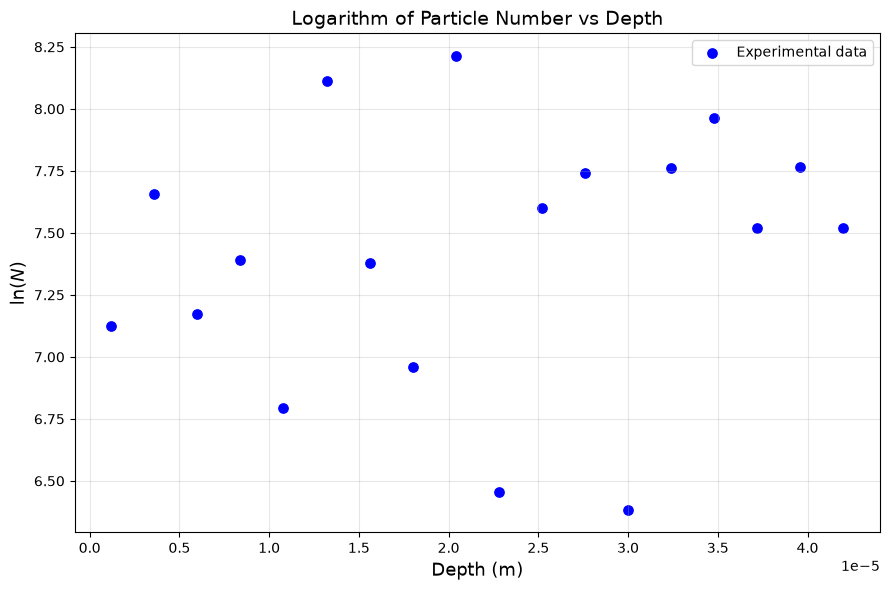


LINEAR FIT RESULTS
----------------------------------------
Slope               = 7.616031e+03 m^-1
Intercept           = 7.252932
R-squared           = 0.035136
Standard error      = 9.977660e+03 m^-1


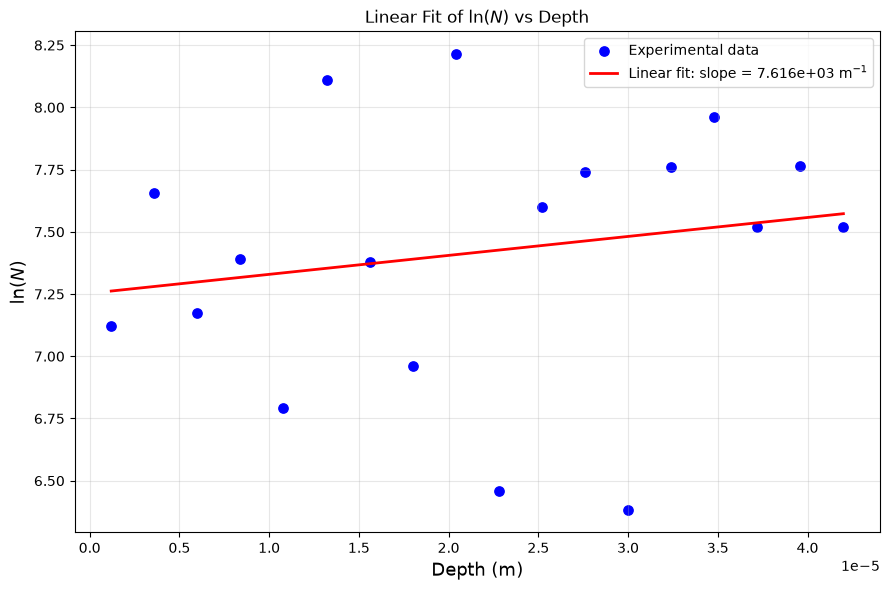


BOLTZMANN CONSTANT
----------------------------------------
Effective force = 1.742302e-14 N
Temperature     = 298.15 K
Slope magnitude = 7.616031e+03 m^-1
Boltzmann constant = 7.672908e-21 J/K

AVOGADRO CONSTANT
----------------------------------------
Gas constant R = 8.314462618 J/(mol K)
Experimental Avogadro constant = 1.083613e+21 mol^-1

ERROR ANALYSIS
----------------------------------------
Accepted k_B = 1.380649e-23 J/K
Experimental k_B = 7.672908e-21 J/K
Relative error in k_B = 55474.6445 %

Accepted N_A = 6.022141e+23 mol^-1
Experimental N_A = 1.083613e+21 mol^-1
Relative error in N_A = 99.8201 %
----------------------------------------


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pims
import trackpy as tp

from scipy.stats import linregress


# ==========================================================
# 1. LOAD EXPERIMENTAL VIDEO
# ==========================================================

video_path = "/home/susanta/Downloads/PICT0097.AVI"

video = pims.open(video_path)

n_frames = len(video)
height, width = video.frame_shape[:2]

fps = getattr(video, 'frame_rate', 15.0)

print("Number of frames:", n_frames)
print("Frame dimensions:", width, "x", height)
print("Frame rate:", fps, "fps")


# ==========================================================
# 2. CONVERT VIDEO INTO GRAYSCALE
# ==========================================================

@pims.pipeline
def gray(image):

    if image.ndim == 3:
        return image[:, :, 1]

    return image


frames = gray(video)

plt.figure(figsize=(9, 5))
plt.imshow(frames[0], cmap='gray')
plt.title("First video frame")
plt.axis('off')
plt.show()


# ==========================================================
# 3. DETECT PARTICLES IN ALL FRAMES
# ==========================================================

features = tp.batch(
    frames,
    diameter=11,
    minmass=1100,
    invert=True,
    processes=1
)

print("\nTotal particle detections:", len(features))


# ==========================================================
# 4. FILTER PARTICLE DETECTIONS
# ==========================================================

features = features[
    (features['mass'] > 1500) &
    (features['size'] < 2.6) &
    (features['ecc'] < 0.3)
].copy()

print("Detections after filtering:", len(features))

print("Number of frames containing detections:",
      features['frame'].nunique())


# ==========================================================
# 5. PHYSICAL PARAMETERS
# ==========================================================

T = 298.15                  # Temperature (K)

g = 9.81                    # Gravitational acceleration (m/s^2)

mpp = 0.12                  # Micrometre per pixel

r_um = 2.0                  # Particle radius (micrometre)

r = r_um * 1e-6             # Radius in metres


# IMPORTANT:
# Replace this with the actual particle density.
# Example: 1050 kg/m^3 for approximately 1.05 g/cm^3.

rho_particle = 1050         # kg/m^3 (example only)

rho_water = 997             # kg/m^3 (approximately at 25 C)


# ==========================================================
# 6. CALCULATE EFFECTIVE MASS AND EFFECTIVE FORCE
# ==========================================================

V = (4/3) * np.pi * r**3

m_eff = (rho_particle - rho_water) * V

F_eff = m_eff * g

print("\nPHYSICAL PARAMETERS")
print("----------------------------------------")

print(f"Particle radius       = {r_um:.3f} micrometre")
print(f"Particle volume       = {V:.6e} m^3")
print(f"Particle density      = {rho_particle:.2f} kg/m^3")
print(f"Water density         = {rho_water:.2f} kg/m^3")

print(f"Effective mass        = {m_eff:.6e} kg")
print(f"Effective force       = {F_eff:.6e} N")


# ==========================================================
# 7. DETERMINE PARTICLE DISTRIBUTION WITH DEPTH
# ==========================================================

# Trackpy coordinates:
# x = horizontal position
# y = vertical position
#
# In an image, y increases downward.
# Therefore, we define depth as increasing downward.

y_pixels = features['y'].to_numpy()

# Convert vertical pixel coordinates into metres.

depth = y_pixels * mpp * 1e-6


# ==========================================================
# 8. DIVIDE THE IMAGE INTO HORIZONTAL STRIPS
# ==========================================================

# Width of each horizontal strip in pixels.

bin_width = 20

depth_edges_pixels = np.arange(
    0,
    height + bin_width,
    bin_width
)

# Count detected particles in each horizontal strip.

counts, edges = np.histogram(
    y_pixels,
    bins=depth_edges_pixels
)

# Calculate the centre of each strip.

depth_centres_pixels = (
    edges[:-1] + edges[1:]
) / 2

# Convert depth into metres.

depth_centres = depth_centres_pixels * mpp * 1e-6


# ==========================================================
# 9. CALCULATE PARTICLE NUMBER DISTRIBUTION
# ==========================================================

# Only positive counts can be used for logarithmic fitting.

valid = counts > 0

depth_fit = depth_centres[valid]

N_fit = counts[valid]

ln_N = np.log(N_fit)


# Create distribution table.

distribution = pd.DataFrame({

    "Depth (m)": depth_fit,

    "Number of particles": N_fit,

    "ln(N)": ln_N

})

print("\nPARTICLE DISTRIBUTION")
print("----------------------------------------")

print(distribution.to_string(index=False))


# ==========================================================
# 10. PLOT ln(N) VS DEPTH
# ==========================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    depth_fit,
    ln_N,
    color='blue',
    s=45,
    label='Experimental data'
)

plt.xlabel("Depth (m)", fontsize=13)

plt.ylabel(r"$\ln(N)$", fontsize=13)

plt.title(
    r"Logarithm of Particle Number vs Depth",
    fontsize=14
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()


# ==========================================================
# 11. LINEAR FIT
# ==========================================================

slope, intercept, r_value, p_value, std_err = linregress(
    depth_fit,
    ln_N
)

ln_N_fit = slope * depth_fit + intercept

print("\nLINEAR FIT RESULTS")
print("----------------------------------------")

print(f"Slope               = {slope:.6e} m^-1")

print(f"Intercept           = {intercept:.6f}")

print(f"R-squared           = {r_value**2:.6f}")

print(f"Standard error      = {std_err:.6e} m^-1")


# Plot experimental data and linear fit.

plt.figure(figsize=(9, 6))

plt.scatter(
    depth_fit,
    ln_N,
    color='blue',
    s=45,
    label='Experimental data'
)

plt.plot(
    depth_fit,
    ln_N_fit,
    'r-',
    linewidth=2,
    label=f'Linear fit: slope = {slope:.3e} m$^{{-1}}$'
)

plt.xlabel("Depth (m)", fontsize=13)

plt.ylabel(r"$\ln(N)$", fontsize=13)

plt.title(r"Linear Fit of $\ln(N)$ vs Depth")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ==========================================================
# 12. CALCULATE BOLTZMANN CONSTANT
# ==========================================================

# Use the magnitude of the slope.
# This works whether the coordinate is defined upward
# or downward.

slope_magnitude = abs(slope)

k_B = F_eff / (T * slope_magnitude)

print("\nBOLTZMANN CONSTANT")
print("----------------------------------------")

print(f"Effective force = {F_eff:.6e} N")

print(f"Temperature     = {T:.2f} K")

print(f"Slope magnitude = {slope_magnitude:.6e} m^-1")

print(f"Boltzmann constant = {k_B:.6e} J/K")


# ==========================================================
# 13. CALCULATE AVOGADRO CONSTANT
# ==========================================================

R = 8.314462618             # J/(mol K)

N_A = R / k_B

print("\nAVOGADRO CONSTANT")
print("----------------------------------------")

print(f"Gas constant R = {R:.9f} J/(mol K)")

print(f"Experimental Avogadro constant = {N_A:.6e} mol^-1")


# ==========================================================
# 14. CALCULATE RELATIVE ERROR
# ==========================================================

k_B_actual = 1.380649e-23

N_A_actual = 6.02214076e23

error_kB = abs(
    (k_B - k_B_actual) / k_B_actual
) * 100

error_NA = abs(
    (N_A - N_A_actual) / N_A_actual
) * 100


print("\nERROR ANALYSIS")
print("----------------------------------------")

print(f"Accepted k_B = {k_B_actual:.6e} J/K")

print(f"Experimental k_B = {k_B:.6e} J/K")

print(f"Relative error in k_B = {error_kB:.4f} %")

print()

print(f"Accepted N_A = {N_A_actual:.6e} mol^-1")

print(f"Experimental N_A = {N_A:.6e} mol^-1")

print(f"Relative error in N_A = {error_NA:.4f} %")

print("----------------------------------------")